# Prediksi Hujan Esok Hari di Jakarta
### Predictive Analytics — Klasifikasi dengan Decision Tree dan Random Forest

**Tujuan analisis:** memprediksi hujan esok hari di Jakarta dari cuaca hari ini, untuk membantu perencanaan aktivitas dan kesiapsiagaan banjir, serta menemukan faktor cuaca yang paling menentukan hujan esok hari.

**Data:** cuaca harian Jakarta dari Open-Meteo (data ERA5), 1 Januari 2019 – 31 Desember 2024 (2.192 hari).

**Hasil utama (diperoleh di notebook ini):**
- Pohon keputusan (Decision Tree): akurasi **81,1%** pada data uji tahun 2024
- Random Forest: akurasi **80,3%**
- Tebakan asal (selalu menebak kelas terbanyak): **70,2%** — model lebih baik +11 poin dari tebakan asal
- Faktor terpenting: curah hujan hari ini, lalu kelembapan dan kecepatan angin

## 1. Sumber Data

Data diambil dari **Open-Meteo Archive API** (https://open-meteo.com), yang menyediakan data cuaca historis ERA5 — hasil gabungan pengamatan dan model cuaca yang dihitung ulang secara konsisten. Lokasi yang dipakai adalah Jakarta (latitude −6,2088, longitude 106,8456), zona waktu Asia/Jakarta.

Kolom data:
| Kolom | Arti |
|---|---|
| `tanggal` | Tanggal pengamatan |
| `suhu_max` | Suhu tertinggi hari itu (°C) |
| `suhu_min` | Suhu terendah hari itu (°C) |
| `hujan_mm` | Total curah hujan hari itu (mm) |
| `lembab` | Kelembapan udara rata-rata (%) |
| `angin_max` | Kecepatan angin maksimum (km/jam) |

In [1]:
import json
import urllib.request
import pandas as pd

# Ambil data cuaca harian Jakarta 2019-2024 dari Open-Meteo Archive API
url = ("https://archive-api.open-meteo.com/v1/archive?"
       "latitude=-6.2088&longitude=106.8456"
       "&start_date=2019-01-01&end_date=2024-12-31"
       "&daily=temperature_2m_max,temperature_2m_min,precipitation_sum,"
       "relative_humidity_2m_mean,wind_speed_10m_max"
       "&timezone=Asia%2FJakarta")

with urllib.request.urlopen(url) as resp:
    raw = json.load(resp)["daily"]

df = pd.DataFrame({
    "tanggal": raw["time"],
    "suhu_max": raw["temperature_2m_max"],
    "suhu_min": raw["temperature_2m_min"],
    "hujan_mm": raw["precipitation_sum"],
    "lembab": raw["relative_humidity_2m_mean"],
    "angin_max": raw["wind_speed_10m_max"],
})
df.to_csv("cuaca_jakarta_2019_2024.csv", index=False)
print("Data tersimpan:", len(df), "hari")

Data tersimpan: 2192 hari


In [2]:
# Muat data (berkas CSV yang sama juga tersedia di repo ini)
df = pd.read_csv("cuaca_jakarta_2019_2024.csv", parse_dates=["tanggal"])
print("Jumlah baris:", len(df))
print("Data hilang:", int(df.isna().sum().sum()))
df.head()

def indo(x, n=1):
    """Format angka memakai koma desimal (gaya Indonesia)."""
    return f"{x:.{n}f}".replace(".", ",")

Jumlah baris: 2192
Data hilang: 0


## 2. Mengenal Data

Sebelum membuat model, kita lihat dulu gambaran datanya: seberapa sering Jakarta hujan, dan bagaimana pola hujan menurut bulan.

In [3]:
print("Rata-rata suhu maksimum : %s °C" % indo(df["suhu_max"].mean()))
print("Rata-rata suhu minimum  : %s °C" % indo(df["suhu_min"].mean()))
print("Rata-rata kelembapan    : %s %%" % indo(df["lembab"].mean(), 0))
print("Rata-rata curah hujan   : %s mm/hari" % indo(df["hujan_mm"].mean()))
hari_hujan = (df["hujan_mm"] >= 1).sum()
print("Hari hujan (>= 1 mm)    : %d dari %d hari (%s%%)" % (hari_hujan, len(df), indo(hari_hujan / len(df) * 100)))

Rata-rata suhu maksimum : 31,7 °C
Rata-rata suhu minimum  : 23,7 °C
Rata-rata kelembapan    : 81 %
Rata-rata curah hujan   : 6,4 mm/hari
Hari hujan (>= 1 mm)    : 1640 dari 2192 hari (74,8%)


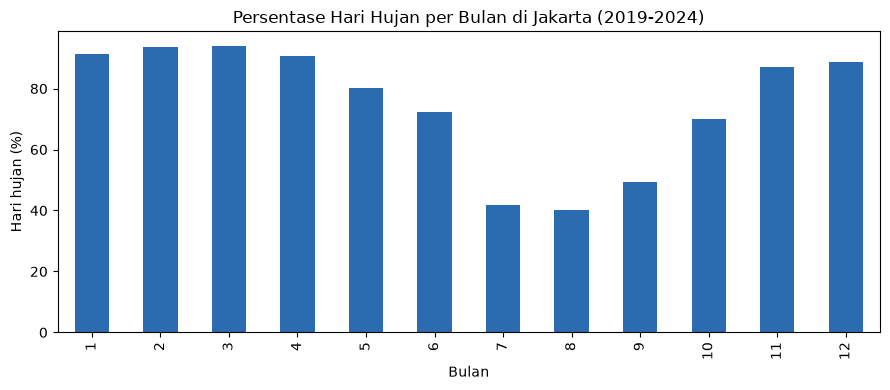

Bulan paling sering hujan: Februari & Maret (sekitar 94%)
Bulan paling jarang hujan: Agustus (sekitar 40%)


In [4]:
import matplotlib.pyplot as plt

df["bulan"] = df["tanggal"].dt.month
persen_hujan = df.assign(hujan=(df["hujan_mm"] >= 1)).groupby("bulan")["hujan"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
persen_hujan.plot(kind="bar", ax=ax, color="#2b6cb0")
ax.set_xlabel("Bulan"); ax.set_ylabel("Hari hujan (%)")
ax.set_title("Persentase Hari Hujan per Bulan di Jakarta (2019-2024)")
plt.tight_layout(); plt.show()

print("Bulan paling sering hujan: Februari & Maret (sekitar 94%)")
print("Bulan paling jarang hujan: Agustus (sekitar 40%)")

## 3. Menyiapkan Target dan Fitur

**Target** yang diprediksi adalah `hujan_besok`:
- `1` bila curah hujan **esok hari** ≥ 1 mm (hujan)
- `0` bila esok hari < 1 mm (cerah)

Batas 1 mm dipakai agar gerimis yang sangat tipis tidak dihitung sebagai hujan.

**Fitur** (informasi dari hari ini yang dipakai untuk menebak besok):
- `hujan_mm` — curah hujan hari ini
- `hujan_hari_ini` — hari ini hujan atau tidak (1/0)
- `lembab` — kelembapan hari ini
- `suhu_max`, `suhu_min` — suhu hari ini
- `angin_max` — kecepatan angin maksimum hari ini
- `bulan` — bulan berjalan (menangkap pola musim)

In [5]:
df["hujan_besok"] = (df["hujan_mm"].shift(-1) >= 1).astype(int)
df["hujan_hari_ini"] = (df["hujan_mm"] >= 1).astype(int)

data = df.dropna().copy()
print("Data siap pakai:", len(data), "baris")
data[["tanggal", "hujan_mm", "lembab", "suhu_max", "hujan_besok"]].head()

Data siap pakai: 2192 baris


,tanggal,hujan_mm,lembab,suhu_max,hujan_besok
0,2019-01-01,5.9,87,27.2,1
1,2019-01-02,2.3,80,31.1,1
2,2019-01-03,9.0,81,30.6,0
3,2019-01-04,0.1,69,32.7,0
4,2019-01-05,0.8,75,31.7,1


## 4. Membagi Data Latih dan Data Uji — Berdasarkan Waktu

Data cuaca adalah data berurutan waktu, jadi pembagiannya **tidak diacak**:
- **Data latih:** 2019–2023 (1.826 hari) — untuk mengajari model
- **Data uji:** 2024 (366 hari) — untuk menguji model pada data yang belum pernah dilihat

Cara ini meniru keadaan sebenarnya: model hanya boleh memakai masa lalu untuk menebak masa depan. Kalau diacak, model bisa "mengintip" hari-hari di sekitar tanggal uji dan akurasinya jadi menipu.

In [6]:
FITUR = ["hujan_mm", "hujan_hari_ini", "lembab", "suhu_max", "suhu_min", "angin_max", "bulan"]

latih = data[data["tanggal"] < "2024-01-01"]
uji = data[data["tanggal"] >= "2024-01-01"]
X_latih, y_latih = latih[FITUR], latih["hujan_besok"]
X_uji, y_uji = uji[FITUR], uji["hujan_besok"]
print("Data latih:", len(latih), "hari | Data uji:", len(uji), "hari")

Data latih: 1826 hari | Data uji: 366 hari


## 5. Baseline: Tebakan Asal

Sebelum menilai model, kita perlu pembanding paling sederhana: **selalu menebak kelas yang paling sering muncul** (di data uji 2024, kelas terbanyak adalah "hujan").

Akurasi tebakan asal ini adalah patokan minimum. Model yang baik harus bisa mengalahkannya dengan jelas — akurasi 81% terdengar bagus, tetapi baru berarti kalau tebakan asal saja tidak sudah tinggi.

In [7]:
from sklearn.metrics import accuracy_score

tebakan_asal = [y_uji.mode()[0]] * len(y_uji)
akurasi_baseline = accuracy_score(y_uji, tebakan_asal)
print("Akurasi tebakan asal (selalu menebak hujan): %s%%" % indo(akurasi_baseline * 100))

Akurasi tebakan asal (selalu menebak hujan): 70,2%


## 6. Model 1 — Decision Tree (Pohon Keputusan)

Pohon keputusan menebak dengan serangkaian pertanyaan ya/tidak, misalnya: "Apakah kelembapan hari ini di atas 85%? Jika ya, apakah curah hujan hari ini di atas 2 mm?" Setiap jawaban membawa ke cabang berikutnya sampai tiba di daun berisi tebakan "hujan" atau "cerah".

Kelebihannya: **seluruh logika model bisa digambar dan dijelaskan** — tidak ada kotak hitam. Kedalaman pohon dibatasi maksimal 5 tingkat agar tidak menghafal data latih.

In [8]:
from sklearn.tree import DecisionTreeClassifier

pohon = DecisionTreeClassifier(max_depth=5, random_state=42)
pohon.fit(X_latih, y_latih)

pred_pohon = pohon.predict(X_uji)
akurasi_pohon = accuracy_score(y_uji, pred_pohon)
print("Akurasi Decision Tree: %s%%" % indo(akurasi_pohon * 100))
print("Keunggulan atas tebakan asal: +%.0f poin" % ((akurasi_pohon - akurasi_baseline) * 100))

Akurasi Decision Tree: 81,1%
Keunggulan atas tebakan asal: +11 poin


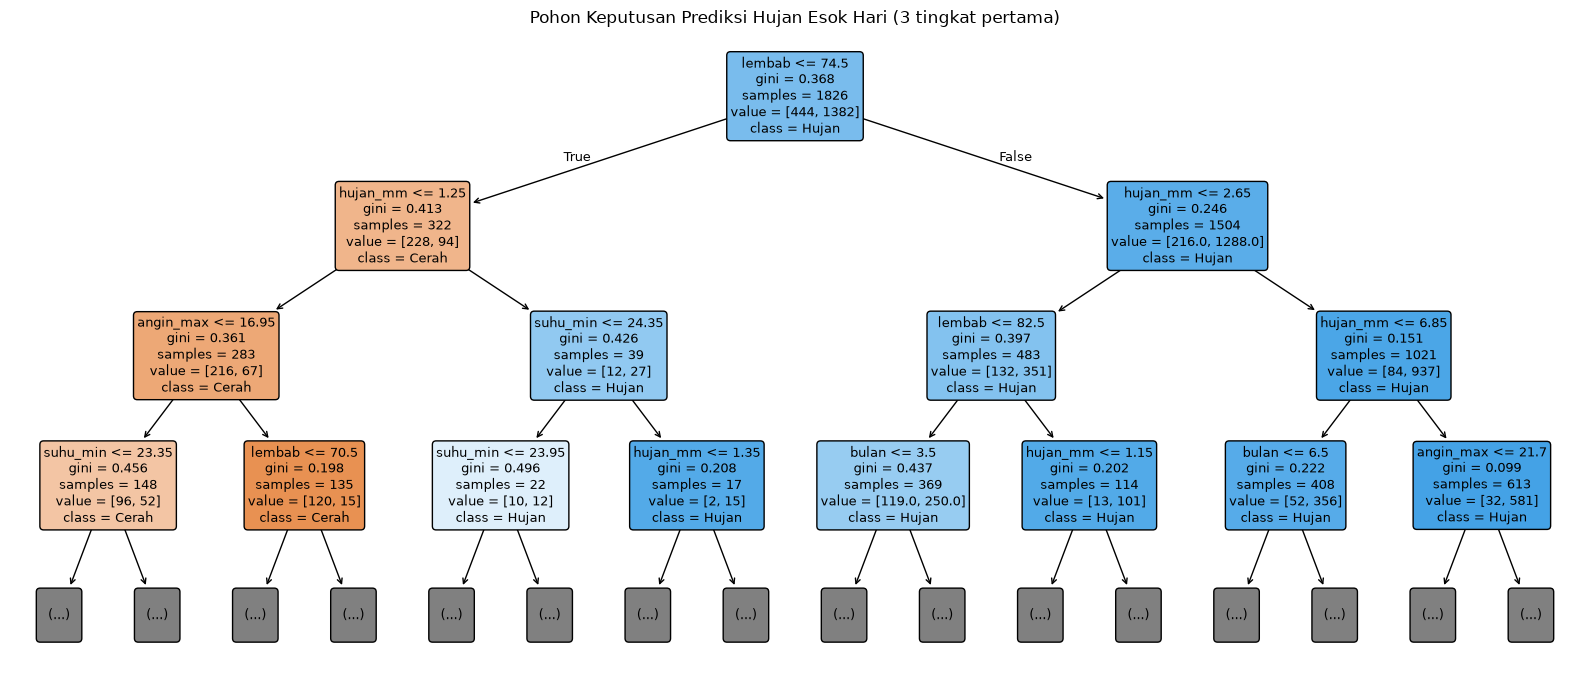

In [9]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(pohon, feature_names=FITUR, class_names=["Cerah", "Hujan"],
          filled=True, rounded=True, fontsize=9, max_depth=3, ax=ax)
ax.set_title("Pohon Keputusan Prediksi Hujan Esok Hari (3 tingkat pertama)")
plt.tight_layout(); plt.show()

## 7. Model 2 — Random Forest

Random Forest membuat 200 pohon keputusan yang masing-masing dilatih dengan sampel dan fitur yang sedikit berbeda, lalu mengambil suara terbanyak. Hasilnya biasanya lebih stabil daripada satu pohon.

Dari model ini kita juga bisa membaca **tingkat kepentingan fitur**: seberapa besar sumbangan tiap faktor dalam menentukan tebakan.

In [10]:
from sklearn.ensemble import RandomForestClassifier

hutan = RandomForestClassifier(n_estimators=200, random_state=42)
hutan.fit(X_latih, y_latih)

pred_hutan = hutan.predict(X_uji)
akurasi_hutan = accuracy_score(y_uji, pred_hutan)
print("Akurasi Random Forest: %s%%" % indo(akurasi_hutan * 100))

kepentingan = pd.Series(hutan.feature_importances_, index=FITUR).sort_values(ascending=False)
print("\nTingkat kepentingan fitur:")
print(kepentingan.round(3))

Akurasi Random Forest: 80,3%

Tingkat kepentingan fitur:
hujan_mm          0.221
lembab            0.193
angin_max         0.155
suhu_max          0.149
suhu_min          0.118
bulan             0.099
hujan_hari_ini    0.065
dtype: float64


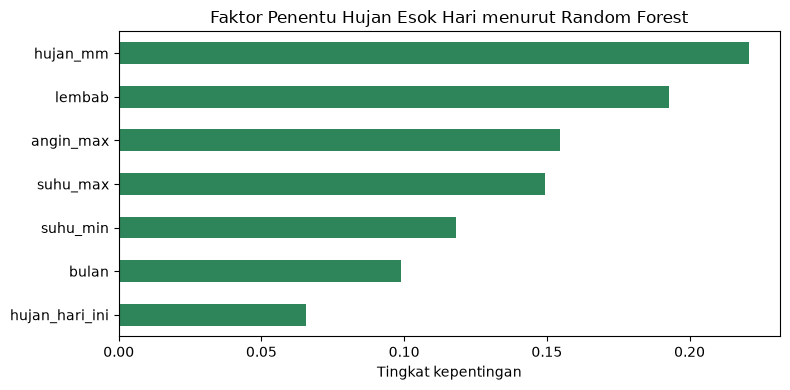

Terpenting: curah hujan hari ini (0,221), kelembapan (0,193), angin (0,155).
Artinya: cuaca hari ini membawa 'momentum' — hari yang basah dan lembap
cenderung diikuti hari hujan berikutnya.


In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
kepentingan.sort_values().plot(kind="barh", ax=ax, color="#2f855a")
ax.set_xlabel("Tingkat kepentingan")
ax.set_title("Faktor Penentu Hujan Esok Hari menurut Random Forest")
plt.tight_layout(); plt.show()

print("Terpenting: curah hujan hari ini (0,221), kelembapan (0,193), angin (0,155).")
print("Artinya: cuaca hari ini membawa 'momentum' — hari yang basah dan lembap")
print("cenderung diikuti hari hujan berikutnya.")

## 8. Evaluasi Lebih Dalam: Confusion Matrix

Akurasi saja tidak cukup. Confusion matrix menunjukkan **jenis kesalahan** model pohon keputusan pada data uji 2024:

- Model menangkap 247 dari 257 hari hujan (96,1%) — jarang melewatkan hujan.
- Tetapi dari 109 hari cerah, hanya 50 yang ditebak benar. Model terlalu sering menerka hujan (59 kali salah menerka hujan pada hari yang ternyata cerah).

Untuk keperluan praktis, kesalahan jenis kedua lebih aman daripada melewatkan hujan (misalnya untuk kesiapsiagaan banjir), tetapi untuk rencana kegiatan luar ruang, terkaan hujan yang keliru tetap mengganggu.

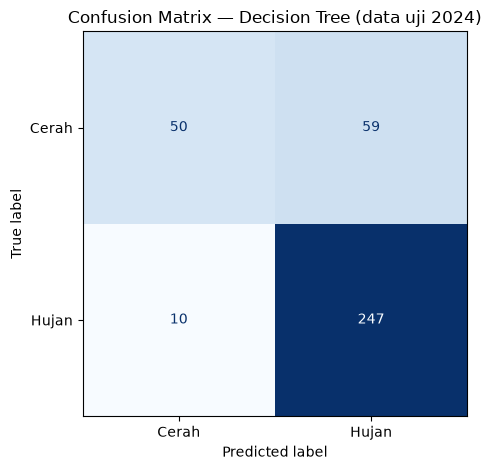

Baris = kenyataan, kolom = prediksi
[[ 50  59]
 [ 10 247]]


In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_uji, pred_pohon)
disp = ConfusionMatrixDisplay(cm, display_labels=["Cerah", "Hujan"])
disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion Matrix — Decision Tree (data uji 2024)")
plt.tight_layout(); plt.show()
print("Baris = kenyataan, kolom = prediksi")
print(cm)

## 9. Hasil menurut Musim

Akurasi model tidak sama sepanjang tahun. Di musim hujan model jauh lebih mudah menebak (karena hampir setiap hari memang hujan), sedangkan di musim kemarau pola hujan lebih tidak menentu.

In [13]:
for nama, bulan_musim in [("Musim hujan (Des-Mar)", [12, 1, 2, 3]), ("Musim kemarau (Jun-Sep)", [6, 7, 8, 9])]:
    bagian = uji[uji["bulan"].isin(bulan_musim)]
    ak = accuracy_score(bagian["hujan_besok"], hutan.predict(bagian[FITUR]))
    print("%s: akurasi Random Forest %s%% (tingkat hujan %s%%)"
          % (nama, indo(ak * 100), indo(bagian["hujan_besok"].mean() * 100, 0)))

Musim hujan (Des-Mar): akurasi Random Forest 88,5% (tingkat hujan 90%)
Musim kemarau (Jun-Sep): akurasi Random Forest 74,6% (tingkat hujan 43%)


## 10. Contoh Pemakaian: Memprediksi Satu Hari

Misalkan pada **20 November 2024** cuacanya: hujan 3,3 mm, kelembapan 80%, suhu 32,8 °C / 24,6 °C, angin maksimum 9,7 km/jam. Apa tebakan model untuk 21 November 2024?

In [14]:
contoh = data[data["tanggal"] == "2024-11-20"]
print("Cuaca 20 Nov 2024: hujan %s mm, lembab %s%%, suhu %s/%s °C, angin %s km/jam"
      % (indo(contoh["hujan_mm"].iloc[0]), indo(contoh["lembab"].iloc[0], 0),
         indo(contoh["suhu_max"].iloc[0]), indo(contoh["suhu_min"].iloc[0]), indo(contoh["angin_max"].iloc[0])))

tebakan = pohon.predict(contoh[FITUR])[0]
besok = df[df["tanggal"] == "2024-11-21"].iloc[0]
print("Prediksi untuk 21 Nov 2024:", "HUJAN" if tebakan == 1 else "CERAH")
print("Kenyataannya: hujan %s mm -> %s" % (indo(besok["hujan_mm"]), "HUJAN (prediksi tepat)" if besok["hujan_mm"] >= 1 else "CERAH"))

Cuaca 20 Nov 2024: hujan 3,3 mm, lembab 80%, suhu 32,8/24,6 °C, angin 9,7 km/jam
Prediksi untuk 21 Nov 2024: HUJAN
Kenyataannya: hujan 5,7 mm -> HUJAN (prediksi tepat)


## 11. Kesimpulan dan Keterbatasan

**Kesimpulan**
1. Hujan esok hari di Jakarta **bisa diprediksi cukup baik dari cuaca hari ini**: pohon keputusan mencapai akurasi 81,1% dan Random Forest 80,3% pada data uji 2024, unggul sekitar 11 poin dari tebakan asal (70,2%).
2. Faktor penentu utamanya adalah **curah hujan hari ini, kelembapan, dan kecepatan angin** — cuaca membawa momentum dari hari ke hari.
3. Model cenderung terlalu sering menerka hujan: hampir tidak pernah melewatkan hari hujan (menangkap 96,1%), tetapi banyak hari cerah yang ikut diterka hujan.
4. Pohon keputusan dipilih sebagai model utama untuk dijelaskan karena akurasinya sedikit lebih tinggi **dan** seluruh logikanya bisa digambar.

**Keterbatasan (perlu disampaikan apa adanya)**
- Akurasi harus selalu dibaca bersama baseline. Di kota yang hampir selalu hujan seperti Pontianak (78,4% hari hujan), tebakan asal saja sudah benar 77% dan model yang sama hanya mencapai 82,5% — unggul hanya +5 poin. Semakin sering hujan di suatu tempat, semakin sulit model terlihat "pintar".
- Data ERA5 adalah hasil gabungan pengamatan dan model cuaca (reanalisis), bukan catatan stasiun pengamatan murni; hujan lokal yang sangat singkat bisa tercatat berbeda dari yang dirasakan di lapangan.
- Prediksi suhu esok hari dengan data ini **tidak berguna** (R² sekitar 0,08) karena suhu Jakarta yang dekat khatulistiwa terlalu stabil dari hari ke hari — tidak ada pola yang bisa dipelajari. Karena itu target analisis ini adalah hujan, bukan suhu.
- Model ini adalah alat belajar predictive analytics, **bukan** pengganti prakiraan BMKG yang memakai model fisika atmosfer, radar, dan satelit secara langsung.